# Predikcia dojazdu elektrických áut: modely

Pokračujeme z notebooku `preprocessing.ipynb`, kde sme dáta rozdelili na tréning a test a pripravili
dva `ColumnTransformer`y. Tu natrénujeme prvé modely a porovnáme ich medzi sebou.

Testovacie dáta v tomto notebooku **nepoužijeme vôbec**. Modely porovnávame iba na trénovacích dátach
cez krížovú validáciu. Test si necháme na úplný koniec, keď budeme mať vybraný a vyladený víťazný model.

## 1. Príprava dát

Rovnaké kroky ako v `preprocessing.ipynb`. Rovnaký `random_state=42` zaručí, že dostaneme presne
to isté rozdelenie na tréning a test.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

data = pd.read_csv('data/ev_clean.csv')
y = data['range_km']
X = data.drop(columns='range_km')

num_col = X.select_dtypes(include='number').columns.tolist()
cat_col = X.select_dtypes(exclude='number').columns.tolist()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, shuffle=True, random_state=42)

def novy_encoder():
    return OneHotEncoder(min_frequency=10, handle_unknown='infrequent_if_exist',
                         sparse_output=False)

prep_skalovany = ColumnTransformer([
    ('num', StandardScaler(), num_col),
    ('cat', novy_encoder(), cat_col),
])

prep_stromy = ColumnTransformer([
    ('num', 'passthrough', num_col),
    ('cat', novy_encoder(), cat_col),
])

print('Tréning:', X_train.shape, ' Test:', X_test.shape)

Tréning: (1268, 8)  Test: (317, 8)


## 2. Ako budeme modely hodnotiť

### 2.1 Metriky

Pre každé auto porovnáme predpovedaný dojazd so skutočným. Rozdiel je **chyba** (reziduum).

- **MAE** (*mean absolute error*): priemer absolútnych chýb v km. Hovorí, o koľko kilometrov sa
  model v priemere mýli. Je to naša hlavná metrika, lebo sa dá ľahko vysvetliť.
- **RMSE** (*root mean squared error*): chyby najprv umocní na druhú, spriemeruje a odmocní. Tiež je
  v km, ale veľké chyby trestá viac ako malé. Keď je RMSE oveľa väčšie ako MAE, model sa pri
  niektorých autách mýli výrazne.
- **R²**: aká časť rozptylu dojazdu je vysvetlená modelom. 1 znamená dokonalú predpoveď, 0 znamená,
  že model nie je lepší ako tipovanie priemeru. Môže vyjsť aj záporne, keď je model ešte horší.

### 2.2 Krížová validácia

Keby sme model vyhodnotili na tých istých dátach, na ktorých sa učil, výsledok by bol príliš optimistický.
Model mohol dáta iba „naspamäť“. Preto trénovacie dáta rozdelíme na 5 častí (*foldov*):

```
fold:     1      2      3      4      5
kolo 1: [VAL] [tré] [tré] [tré] [tré]
kolo 2: [tré] [VAL] [tré] [tré] [tré]
...
kolo 5: [tré] [tré] [tré] [tré] [VAL]
```

V každom kole sa model naučí na 4 častiach a ohodnotí sa na piatej (validačnej), ktorú nevidel.
Výsledkom je 5 hodnôt každej metriky. Ich priemer je odhad, ako model zvládne nové autá, a smerodajná
odchýlka ukazuje, ako veľmi výsledok závisí od toho, ktoré autá padli do validácie.

Model je v `Pipeline` spolu s `ColumnTransformer`om. Krížová validácia tak v každom kole naučí scaler
aj encoder znova a iba na 4 trénovacích častiach. Validačná časť sa do učenia nedostane ani cez priemery
pre scaler (žiadny *data leakage*).

In [2]:
from sklearn.model_selection import KFold, cross_validate

cv = KFold(n_splits=5, shuffle=True, random_state=42)

# sklearn chce metriky, kde je „väčšie = lepšie“, preto chyby vracia so záporným znamienkom
metriky = {
    'MAE': 'neg_mean_absolute_error',
    'RMSE': 'neg_root_mean_squared_error',
    'R2': 'r2',
}

def vyhodnot(nazov, model, cv=cv, groups=None):
    vysledky = cross_validate(model, X_train, y_train, cv=cv, groups=groups,
                              scoring=metriky, return_train_score=True)
    return {
        'model': nazov,
        'MAE': -vysledky['test_MAE'].mean(),
        'MAE std': vysledky['test_MAE'].std(),
        'RMSE': -vysledky['test_RMSE'].mean(),
        'R2': vysledky['test_R2'].mean(),
        'MAE tréning': -vysledky['train_MAE'].mean(),
    }

## 3. Baseline: tipovanie priemeru

`DummyRegressor` sa z príznakov nič neučí. Pre každé auto predpovie ten istý dojazd, priemer
`y_train`. Je to latka: model, ktorý ju neprekoná, je zbytočný.

In [3]:
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyRegressor

baseline = Pipeline([
    ('prep', prep_stromy),
    ('model', DummyRegressor(strategy='mean')),
])

vysledky = [vyhodnot('Baseline (priemer)', baseline)]
pd.DataFrame(vysledky).round(3)

,model,MAE,MAE std,RMSE,R2,MAE tréning
0,Baseline (priemer),85.804,2.315,119.571,-0.013,85.611


Tipovanie priemeru sa mýli v priemere o vyše 80 km a R² je približne 0, ako sme čakali.

## 4. Modely

Každý model dáme do `Pipeline` s vhodným transformerom:

- **`Ridge`** (+ `prep_skalovany`): lineárna regresia, dojazd = súčet príznakov vynásobených váhami.
  Navyše trestá príliš veľké váhy (*L2 regularizácia*, sila `alpha=1`), čo pomáha pri desiatkach
  one-hot stĺpcov. Potrebuje škálované čísla, inak by trestal váhy nerovnomerne.
- **`RandomForestRegressor`** (+ `prep_stromy`): 100 rozhodovacích stromov, každý sa učí na inom
  náhodnom výbere áut. Výsledok je priemer ich predpovedí. Vie zachytiť nelineárne vzťahy.
- **`GradientBoostingRegressor`** (+ `prep_stromy`): stromy sa učia postupne a každý ďalší opravuje
  chyby tých predchádzajúcich. Predvolene 100 plytkých stromov (hĺbka 3).

Zatiaľ nechávame predvolené nastavenia. Ladenie hyperparametrov príde v ďalšom kroku.
`random_state=42` zaručí rovnaké výsledky pri každom spustení.

In [4]:
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

modely = {
    'Ridge': Pipeline([
        ('prep', prep_skalovany),
        ('model', Ridge(alpha=1.0)),
    ]),
    'Random Forest': Pipeline([
        ('prep', prep_stromy),
        ('model', RandomForestRegressor(random_state=42, n_jobs=-1)),
    ]),
    'Gradient Boosting': Pipeline([
        ('prep', prep_stromy),
        ('model', GradientBoostingRegressor(random_state=42)),
    ]),
}

for nazov, model in modely.items():
    vysledky.append(vyhodnot(nazov, model))

porovnanie = pd.DataFrame(vysledky).set_index('model').sort_values('MAE')
porovnanie.round(3)

,MAE,MAE std,RMSE,R2,MAE tréning
model,,,,,
Random Forest,20.919,1.105,34.715,0.912,7.867
Gradient Boosting,31.170,1.080,43.023,0.867,25.064
Ridge,37.482,2.195,48.809,0.829,35.911
Baseline (priemer),85.804,2.315,119.571,-0.013,85.611


## 5. Porovnanie

Graf ukazuje priemerné MAE z 5 foldov. Čiarka na konci stĺpca je smerodajná odchýlka medzi foldmi.

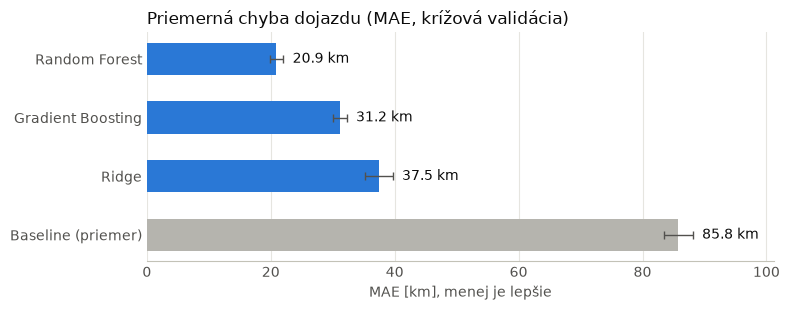

In [5]:
MODRA, ORANZOVA, SIVA = '#2a78d6', '#eb6834', '#b5b4ae'
TEXT, TEXT_2 = '#0b0b0b', '#52514e'

poradie = porovnanie.sort_values('MAE', ascending=False)
farby = [SIVA if 'Baseline' in nazov else MODRA for nazov in poradie.index]

fig, ax = plt.subplots(figsize=(8, 3.2))
ax.barh(poradie.index, poradie['MAE'], xerr=poradie['MAE std'], height=0.55,
        color=farby, error_kw={'ecolor': TEXT_2, 'elinewidth': 1, 'capsize': 3})
for i, (mae, std) in enumerate(zip(poradie['MAE'], poradie['MAE std'])):
    ax.text(mae + std + 1.5, i, f'{mae:.1f} km', va='center', color=TEXT, fontsize=10)

ax.set_title('Priemerná chyba dojazdu (MAE, krížová validácia)', loc='left', color=TEXT)
ax.set_xlabel('MAE [km], menej je lepšie', color=TEXT_2)
ax.set_xlim(0, poradie['MAE'].max() * 1.18)
ax.tick_params(colors=TEXT_2, length=0)
ax.grid(axis='x', color='#e6e5e0', linewidth=0.8)
ax.set_axisbelow(True)
for strana in ['top', 'right', 'left']:
    ax.spines[strana].set_visible(False)
ax.spines['bottom'].set_color('#c3c2b7')
plt.tight_layout()
plt.show()

### 5.1 Tréningová vs. validačná chyba

`cross_validate` s `return_train_score=True` vráti aj chybu na tých častiach, na ktorých sa model učil.
Porovnanie oboch chýb ukáže, ako sa model správa:

- **Obe chyby veľké:** model je príliš jednoduchý a vzťahy v dátach nezachytil (*underfitting*).
- **Tréningová chyba malá, validačná oveľa väčšia:** model si dáta pamätá naspamäť (*overfitting*).
- **Obe malé a blízko seba:** to chceme.

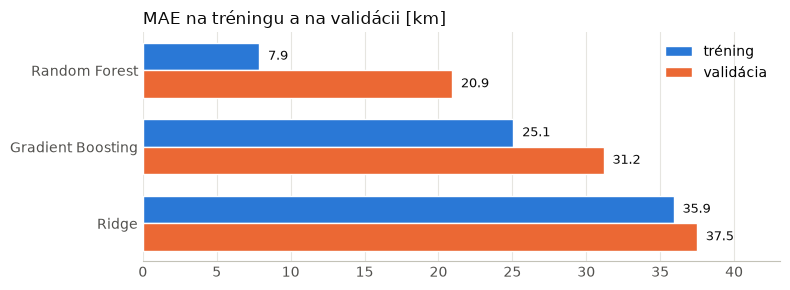

In [6]:
modely_bez_baseline = porovnanie.drop(index='Baseline (priemer)').sort_values('MAE', ascending=False)
pozicie = range(len(modely_bez_baseline))
vyska = 0.36

fig, ax = plt.subplots(figsize=(8, 3))
ax.barh([p + vyska / 2 for p in pozicie], modely_bez_baseline['MAE tréning'], height=vyska,
        color=MODRA, label='tréning', edgecolor='white', linewidth=1)
ax.barh([p - vyska / 2 for p in pozicie], modely_bez_baseline['MAE'], height=vyska,
        color=ORANZOVA, label='validácia', edgecolor='white', linewidth=1)
for p, (tren, val) in zip(pozicie, zip(modely_bez_baseline['MAE tréning'], modely_bez_baseline['MAE'])):
    ax.text(tren + 0.6, p + vyska / 2, f'{tren:.1f}', va='center', color=TEXT, fontsize=9)
    ax.text(val + 0.6, p - vyska / 2, f'{val:.1f}', va='center', color=TEXT, fontsize=9)

ax.set_yticks(list(pozicie), modely_bez_baseline.index)
ax.set_title('MAE na tréningu a na validácii [km]', loc='left', color=TEXT)
ax.set_xlim(0, modely_bez_baseline['MAE'].max() * 1.15)
ax.legend(frameon=False, loc='upper right')
ax.tick_params(colors=TEXT_2, length=0)
ax.grid(axis='x', color='#e6e5e0', linewidth=0.8)
ax.set_axisbelow(True)
for strana in ['top', 'right', 'left']:
    ax.spines[strana].set_visible(False)
ax.spines['bottom'].set_color('#c3c2b7')
plt.tight_layout()
plt.show()

## 6. Kontrola: autá s rovnakými príznakmi

V `analyza.ipynb` sme našli 108 riadkov, ktoré sú po odstránení názvu modelu úplne rovnaké
(napríklad viac verzií toho istého auta s rovnakým motorom, batériou aj dojazdom). Keď jedno také auto
padne do tréningu a jeho „dvojča“ do validácie, model nemusí nič predpovedať. Stačí, keď si dvojča
zapamätá. Výsledok by tak mohol vyjsť lepší, ako v skutočnosti je.

Overíme to cez **`GroupKFold`**: každá jedinečná kombinácia príznakov dostane vlastnú skupinu a autá
z tej istej skupiny skončia vždy v tom istom folde. Dvojčatá sa tak nikdy nerozdelia medzi tréning a validáciu.

In [7]:
from sklearn.model_selection import GroupKFold

# z každého riadku urobíme text, napr. '2024|BMW|...', rovnaké autá dostanú rovnaký text = rovnakú skupinu
skupiny = X_train.astype(str).agg('|'.join, axis=1)
print(f'{len(X_train)} áut v tréningu, {skupiny.nunique()} jedinečných kombinácií príznakov')

cv_skupiny = GroupKFold(n_splits=5, shuffle=True, random_state=42)
vysledky_skupiny = [vyhodnot(nazov, model, cv=cv_skupiny, groups=skupiny)
                    for nazov, model in modely.items()]

pd.DataFrame({
    'MAE (KFold)': porovnanie['MAE'],
    'MAE (GroupKFold)': pd.DataFrame(vysledky_skupiny).set_index('model')['MAE'],
}).drop(index='Baseline (priemer)').round(1)

1268 áut v tréningu, 1186 jedinečných kombinácií príznakov


,MAE (KFold),MAE (GroupKFold)
model,,
Gradient Boosting,31.2,30.9
Random Forest,20.9,20.9
Ridge,37.5,38.4


Výsledky sa takmer nelíšia, takže dvojčatá výsledok nekreslia lepší, než je. Ďalej preto môžeme
používať obyčajný `KFold`.

## 7. Zhrnutie

- Všetky tri modely jasne prekonali baseline.
- **Random Forest** je najlepší: mýli sa v priemere asi o 21 km pri priemernom dojazde ~448 km
  (približne 5 %) a vysvetlí ~91 % rozptylu dojazdu.
- **Ridge** je najslabší. Lineárny model nezachytí nelineárne vzťahy, ktoré sme videli v analýze.
- **Gradient Boosting** s predvolenými 100 plytkými stromami je medzi nimi. Jeho tréningová aj
  validačná chyba sú pomerne veľké, takže je skôr príliš jednoduchý a viac stromov alebo hlbšie
  stromy by mu mohli pomôcť.
- **Random Forest** má tréningovú chybu oveľa menšiu ako validačnú. Pri náhodnom lese je to bežné,
  lebo jeho stromy rastú do plnej hĺbky. Rozhoduje však validačná chyba a tá je stále najlepšia.

## 8. Ďalší krok

1. **Ladenie** Random Forestu a Gradient Boostingu cez `GridSearchCV` (počet a hĺbka stromov,
   learning rate, minimálny počet áut v liste).
2. **Finálne vyhodnotenie** víťazného modelu na testovacích dátach, iba raz.
3. **Rozbor chýb:** graf predpovedaný vs. skutočný dojazd a ktoré príznaky model používa najviac.